# Phase 3 — Is the KO / PEP relationship stable?

**What the brief asks.** The hedge ratio β of Phase 2 is only an estimate: the true relationship between
the two stocks "can drift or break down entirely over time". Pick **one** way to check it (simple: a
rolling correlation; medium: a rolling hedge ratio and/or a rolling stationarity test), flag the periods
where the relationship looks weak, then answer one question: **does the Phase 2 signal perform worse
during the periods flagged as weak?**

**Result**
- The hedge ratio is far from stable: re-estimated on 2-year windows it ranges from −0.07 to 0.75 inside
  2000–2018 and falls to −0.23 in 2025, against the frozen 0.388.
- The flags built from a rolling stationarity test do **not** separate good trades from bad ones: the
  label fixed in advance calls almost every day "weak"; a relative label gives a small difference, not
  significant, whose sign changes with the window.
- **Answer to the brief: no evidence that the signal does worse in the flagged periods.** The label does
  catch the 2025 break, but the strategy lost just as much in "normal" periods.

**ADF test** (Augmented Dickey-Fuller): the standard test of stationarity, i.e. of whether a series keeps
coming back to a fixed average; its p-value is low when the data say "comes back", high when they cannot
tell it apart from a drift. Other terms: README glossary. **Everything here about 2019–2026 is analysis
after the single out-of-sample run of Phase 2**: nothing in this notebook changes the strategy.

## 1. Set-up and data

Same prices as Phase 2, now 2000–2026. The two backtests are exactly the Phase 2 runs of the frozen
strategy (threshold 1.5, window 60, exit 0, β 0.388372), re-run, not changed: the cell checks they give
the Phase 2 Sharpe ratios (0.35 and −0.53).

In [1]:
import logging

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

from pairs.backtest import run_zscore_strategy, summarize
from pairs.config import PAIR, PHASE2_STRATEGY, Settings
from pairs.data import load_pair_prices
from pairs.explore import select_until
from pairs.logging_setup import configure_logging
from pairs.plots import finish_figure, save_figure
from pairs.spread import build_spread, fit_hedge_ratio
from pairs.stability import (
    compare_groups,
    pvalue_cutoff,
    rolling_adf_pvalue,
    rolling_hedge_ratio,
    trade_returns,
    weak_labels,
)
from pairs.trials import count_trials, log_trial

configure_logging(logging.WARNING)  # notebook output: tables and charts only, no progress logs
pio.renderers.default = "plotly_mimetype+png"
settings = Settings.from_env()
figures_dir = settings.results_dir / "figures"
trials_db = settings.results_dir / "trials.sqlite"
SOURCE = (
    "Source: Yahoo Finance adjusted close, 3 Jan 2000 - 9 Oct 2026."
    " Shaded: out-of-sample (after the single run)."
)
A, B, PAIR_NAME, S = (
    PAIR.ticker_a,
    PAIR.ticker_b,
    f"{PAIR.ticker_a}/{PAIR.ticker_b}",
    PHASE2_STRATEGY,
)


prices = load_pair_prices(PAIR, settings.data_dir, PAIR.end)
is_prices = select_until(prices, PAIR.in_sample_end)
assert abs(fit_hedge_ratio(prices, A, B, PAIR.in_sample_end).beta - S.beta) < 1e-6  # the frozen β
is_start = is_prices.index[249]  # same first day as Phase 2 (first full 250-day window of the grid)
oos_start = prices.index[prices.index > pd.Timestamp(PAIR.in_sample_end)][0]
runs = {
    "in-sample": run_zscore_strategy(
        is_prices, A, B, S.beta, S.entry, S.window, is_start, S.exit
    ).loc[is_start:],
    "out-of-sample": run_zscore_strategy(
        prices, A, B, S.beta, S.entry, S.window, oos_start, S.exit
    ).loc[oos_start:],
}
stats = {name: summarize(run["ret"], run["position"]) for name, run in runs.items()}
pd.DataFrame(stats).loc[["sharpe", "t_stat", "ann_return", "n_trades"]].round(3)

,in-sample,out-of-sample
sharpe,0.351,-0.534
t_stat,1.490,-1.486
ann_return,0.024,-0.038
n_trades,94.000,36.000


## 2. Why check, and which method

**Where Phase 2 left off.** The spread check was "an honest no": the spread moves in waves of several
years, a deviation takes about 192 trading days to halve, and the Engle-Granger test does not reject a
drifting spread (p = 0.12). The strategy still earned a little in-sample because its z-score is measured
against the spread's **60-day rolling average**, which follows the slow waves: it bets on short swings
around the recent level, not on a return to a fixed long-run level. Out-of-sample it lost, while the
KO/PEP price ratio went from 0.35 to 0.56. Phase 3 asks whether those losses come from periods where the
relationship itself was weak.

**Method: the medium option** (rolling hedge ratio + rolling ADF test). The simple option, a rolling
correlation of **daily returns**, does not see the kind of failure I have: two stocks can keep moving
together day by day (Phase 1: correlation 0.51 on average, at its highest after 2007) while the ratio of
their **price levels** slides for years, and the strategy bets on levels. Honest caveat: I chose the
method knowing the cause of the out-of-sample loss (Phase 2, section 7), so the choice follows the
mechanism, not a blind pick.

**Window: 500 trading days (about 2 years)** for both the rolling β and the ADF test. The half-life is
192 days: on one year the spread comes back to its average at most once, too little for any test to
call it stationary; 500 days are about 2.6 half-lives. 250 and 750 days are shown as sensitivity
(section 7).

## 3. The rolling hedge ratio

Every day, OLS of KO on PEP on the last 500 trading days (today included). Descriptive only: it is never
used to trade.

**How to read it:** if the relationship were stable, the line would stay near the dashed β = 0.388
frozen in Phase 2. Far from it means that, in that period, a different mix of the two stocks would have
made the spread flat.

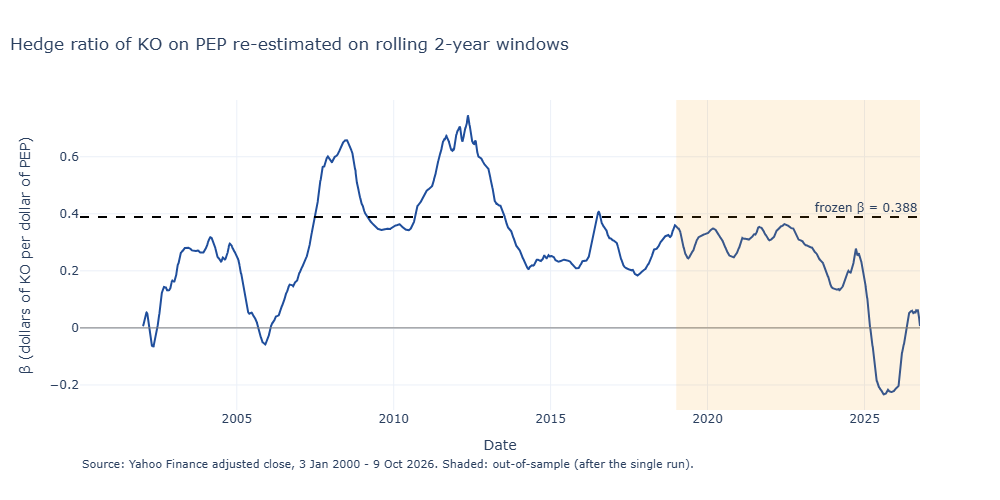

,"rolling β, 500 days"
in-sample minimum,-0.067 (2002-05-08)
in-sample maximum,0.745 (2012-05-14)
in-sample days within ±0.1 of 0.388,30.0%
out-of-sample minimum,-0.234 (2025-08-14)
last value (9 Oct 2026),0.006


In [2]:
BETA_WINDOW = 500
rolling_beta = rolling_hedge_ratio(prices, A, B, BETA_WINDOW)
beta_is, beta_oos = (
    rolling_beta.loc[: pd.Timestamp(PAIR.in_sample_end)].dropna(),
    rolling_beta.loc[oos_start:],
)

fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=rolling_beta.index,
        y=rolling_beta,
        name="β on the last 500 days",
        line={"color": "#1f4e9c"},
    )
)
fig.add_hline(y=S.beta, line_dash="dash", line_color="black", annotation_text="frozen β = 0.388")
fig.add_hline(y=0, line_color="grey", line_width=1)
fig.add_vrect(x0=oos_start, x1=prices.index[-1], fillcolor="#f39c12", opacity=0.12, line_width=0)
finish_figure(
    fig,
    "Hedge ratio of KO on PEP re-estimated on rolling 2-year windows",
    "Date",
    "β (dollars of KO per dollar of PEP)",
    SOURCE,
)
save_figure(fig, "03_rolling_beta", figures_dir)
fig.show()
pd.Series(
    {
        "in-sample minimum": f"{beta_is.min():.3f} ({beta_is.idxmin().date()})",
        "in-sample maximum": f"{beta_is.max():.3f} ({beta_is.idxmax().date()})",
        "in-sample days within ±0.1 of 0.388": f"{(beta_is - S.beta).abs().lt(0.1).mean():.1%}",
        "out-of-sample minimum": f"{beta_oos.min():.3f} ({beta_oos.idxmin().date()})",
        "last value (9 Oct 2026)": f"{rolling_beta.iloc[-1]:.3f}",
    }
).to_frame("rolling β, 500 days")

**Reading.** The relationship is **not stable at a 2-year horizon, not even in-sample**. β goes from
−0.07 (May 2002) to 0.75 (May 2012), and only 30% of in-sample days are within ±0.1 of the frozen 0.388:
that number is an average of very different periods, not a constant of the pair. Out-of-sample β falls to
−0.23 (August 2025): over those two years KO and PEP moved in **opposite** directions, so no positive β
could have made the spread flat. This is the break that sank the out-of-sample run.

This answers the brief's first worry (β drifts), but not yet its question: are the **trades** worse when
the relationship is weak? For that I need a daily label.

## 4. The rolling stationarity test, and the label fixed in advance

Every week (every 5 trading days; the days in between keep the last value), ADF test on the last 500
days of the spread `KO − 0.388 × PEP`, the spread the strategy actually trades.

**Label fixed before computing it** (written down at 14:05): a day is "weak" if the ADF p-value is **above
0.10**, i.e. on the last two years the test cannot say the spread comes back to its average. The label
of day t uses data up to t−1 only, so it was known before that day's trading decision.

**How to read the chart:** low p-value = the last two years look mean-reverting; high = they look like
a drift. Below the red line (0.10) the absolute rule calls the period normal.

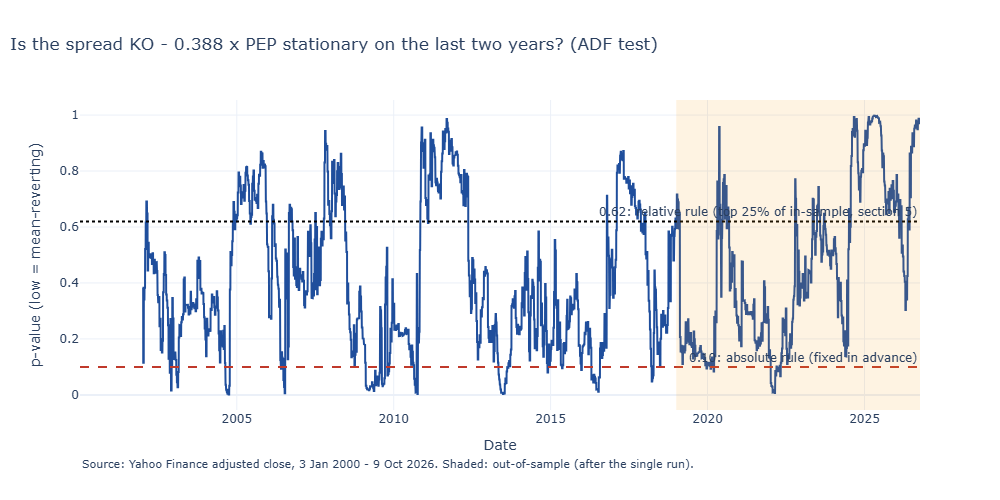

,in-sample,out-of-sample
median p-value,0.346,0.425
share of days with p < 0.10,0.104,0.046


In [3]:
ADF_WINDOW = 500
pvalues = {w: rolling_adf_pvalue(build_spread(prices, A, B, S.beta), w) for w in (250, 500, 750)}
pv = pvalues[ADF_WINDOW]
cutoffs = {w: pvalue_cutoff(p, PAIR.in_sample_end, share=0.25) for w, p in pvalues.items()}

fig = go.Figure()
fig.add_trace(
    go.Scatter(x=pv.index, y=pv, name="ADF p-value, last 500 days", line={"color": "#1f4e9c"})
)
fig.add_hline(
    y=0.10,
    line_dash="dash",
    line_color="#c0392b",
    annotation_text="0.10: absolute rule (fixed in advance)",
)
fig.add_hline(
    y=cutoffs[ADF_WINDOW],
    line_dash="dot",
    line_color="black",
    annotation_text=f"{cutoffs[ADF_WINDOW]:.2f}: relative rule (top 25% of in-sample, section 5)",
)
fig.add_vrect(x0=oos_start, x1=prices.index[-1], fillcolor="#f39c12", opacity=0.12, line_width=0)
finish_figure(
    fig,
    "Is the spread KO - 0.388 x PEP stationary on the last two years? (ADF test)",
    "Date",
    "p-value (low = mean-reverting)",
    SOURCE,
)
save_figure(fig, "03_adf_pvalue", figures_dir)
fig.show()
pv_is, pv_oos = pv.loc[: pd.Timestamp(PAIR.in_sample_end)].dropna(), pv.loc[oos_start:]
pd.DataFrame(
    {
        "in-sample": {
            "median p-value": round(pv_is.median(), 3),
            "share of days with p < 0.10": round(pv_is.lt(0.10).mean(), 3),
        },
        "out-of-sample": {
            "median p-value": round(pv_oos.median(), 3),
            "share of days with p < 0.10": round(pv_oos.lt(0.10).mean(), 3),
        },
    }
)

**Reading: the label fixed in advance does not work.** On 2-year windows the test calls the spread
stationary on only **10% of in-sample days** and 5% of out-of-sample days. So the absolute rule flags
about 90% of the in-sample as "weak", including the years in which the strategy made money (the numbers
are in section 6). A label that is on almost every day cannot separate anything.

**Why, and what it means for Phase 2.** It is the same finding as Phase 2's Engle-Granger test, seen
window by window, not a new error: the spread does not come back to a **fixed** level. Two readings are
possible and the test cannot tell them apart: the spread truly drifts, or it reverts too slowly (half-life
192 days) for two years of data to show it. Either way, the strategy never traded a "stationary" spread:
its z-score bets on swings around a **moving** 60-day average, a different and weaker property that the
ADF test does not measure.

## 5. One relative label, declared after the first one failed

The absolute rule failed for a mechanical reason (the test almost never says "stationary" on this pair),
not because of the returns. I replace it with **one** relative rule and no other:

**"Weak" = the p-value is in the highest 25% of its in-sample values** (above the 75th percentile of the
2002–2018 p-values, frozen and reused unchanged on 2019–2026). It asks "is the spread less mean-reverting
than usual?" instead of "is it mean-reverting?", the same logic as the brief's simple method ("drops well
below its historical norm"). By construction it flags about a quarter of the in-sample days.

**Declared honestly:**
- This rule is **post-hoc**: it was decided at 14:20, after seeing the numbers of the absolute rule
  (including how its trades split), and before computing its own. The 25% was chosen to get two groups
  of usable size, not from any return.
- **Prediction written before computing it**: if a weak relationship explains the losses, trades opened
  in the weak quartile earn less than the others, both in-sample and out-of-sample.
- Nothing is tuned: one share (25%), the same three windows, and every comparison goes into the trial
  log (section 9).
- The cutoff uses all in-sample p-values, so 2005 is labelled with a threshold that "knows" 2018: an
  in-sample calibration, like the β itself.

## 6. The brief's question: does the signal perform worse in weak periods?

**Main comparison, per trade.** Each trade of the frozen strategy gets the label of its **entry day**
(known the day before), and I compare the average trade return of the two groups. This is the honest
version of the question: could you have known, when opening the trade, that it was a bad time?
The 4 in-sample trades of 2001 have no label (the first 500-day window ends on 31 Dec 2001) and are left out.

In [4]:
def compare_trades(run: pd.DataFrame, labels: pd.Series) -> dict[str, float]:
    trades = trade_returns(run)
    entry_label = labels.reindex(trades["entry"]).set_axis(trades.index)
    out = compare_groups(trades["ret"], entry_label)
    out["share_weak_days"] = float(labels.reindex(run.index).mean())
    return out


def compare_days(run: pd.DataFrame, labels: pd.Series) -> dict[str, float]:
    held = (
        run["position"].shift(1).fillna(0.0).ne(0)
    )  # a day's return comes from yesterday's position
    return compare_groups(run["ret"][held], labels.shift(1).reindex(run.index)[held])


rules = {
    "absolute (p > 0.10)": {w: weak_labels(p, 0.10) for w, p in pvalues.items()},
    "relative (top 25% in-sample)": {w: weak_labels(p, cutoffs[w]) for w, p in pvalues.items()},
}
trade_cmp = {
    (rule, w, name): compare_trades(run, labels[w])
    for rule, labels in rules.items()
    for w in pvalues
    for name, run in runs.items()
}


def trade_table(window: int) -> pd.DataFrame:
    rows = {}
    for (rule, w, name), c in trade_cmp.items():
        if w == window:
            rows[(rule, name)] = {
                "weak days": f"{c['share_weak_days']:.0%}",
                "trades weak / normal": f"{c['n_weak']:.0f} / {c['n_normal']:.0f}",
                "avg trade weak": f"{c['mean_weak']:+.2%}",
                "avg trade normal": f"{c['mean_normal']:+.2%}",
                "winners weak / normal": f"{c['win_weak']:.0%} / {c['win_normal']:.0%}",
                "Welch t (weak - normal)": round(c["welch_t"], 2),
            }
    return pd.DataFrame(rows).T


trade_table(ADF_WINDOW)

weak days trades weak / normal  \
absolute (p > 0.10)          in-sample           90%               81 / 9   
                             out-of-sample       95%               33 / 3   
relative (top 25% in-sample) in-sample           25%              20 / 70   
                             out-of-sample       33%              11 / 25   

                                           avg trade weak avg trade normal  \
absolute (p > 0.10)          in-sample             +0.51%           -0.05%   
                             out-of-sample         -0.59%           -3.05%   
relative (top 25% in-sample) in-sample             +0.05%           +0.57%   
                             out-of-sample         -0.68%           -0.85%   

                                           winners weak / normal  \
absolute (p > 0.10)          in-sample                 80% / 56%   
                             out-of-sample              70% / 0%   
relative (top 25% in-sample) in-sample                 70% / 80%   
                             out-of-sample             73% / 60%   

                                           Welch t (weak - normal)  
absolute (p > 0.10)          in-sample                        0.89  
                             out-of-sample                     1.4  
relative (top 25% in-sample) in-sample                       -1.07  
                             out-of-sample                    0.12

**How to read the table:** "avg trade" is the average return of one trade from opening to closing.
The brief's hypothesis predicts *weak < normal*, i.e. a **negative** Welch t.

**Reading.**
- **Absolute rule:** 81 in-sample trades are "weak" and only 9 "normal" (out-of-sample 33 and 3). With 3
  or 9 trades in a group no comparison means anything. For the record, the sign is the opposite of the
  hypothesis (weak trades earn more), and not significant.
- **Relative rule, in-sample:** the prediction goes in the right direction: trades opened in the weak
  quartile earn on average **+0.05%** against **+0.57%** for the others, 70% winners against 80%. But the
  difference is about one standard error (t = −1.07): it can be luck.
- **Relative rule, out-of-sample (analysis after the single run):** no difference: −0.68% against
  −0.85% (t = 0.12). **On average the out-of-sample losses are spread over normal and weak periods
  alike** (the chart below shows where they fall year by year).

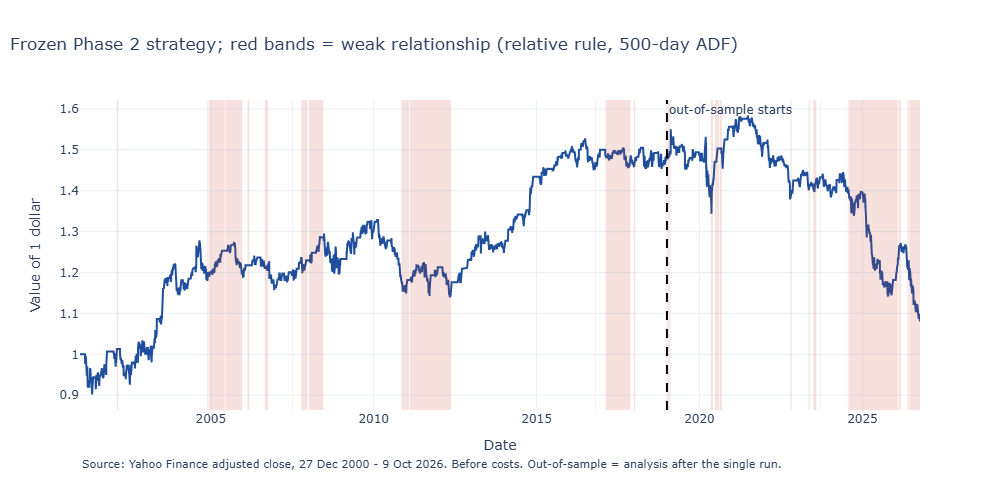

,2019-2024,2025-2026,whole out-of-sample
weak days (share),17%,86%,33%
log return on weak days,0.127,-0.193,-0.066
log return on normal days,-0.188,-0.064,-0.252


In [5]:
# Frozen strategy (in-sample, then out-of-sample); weak days of the relative rule shaded
weak_rel = rules["relative (top 25% in-sample)"][ADF_WINDOW]
equity = (1 + pd.concat([runs["in-sample"]["ret"], runs["out-of-sample"]["ret"]])).cumprod()
flag = weak_rel.reindex(equity.index).eq(1)
blocks = (flag != flag.shift()).cumsum()[flag]
fig = go.Figure()
for _, days in blocks.groupby(blocks):
    fig.add_vrect(
        x0=days.index[0], x1=days.index[-1], fillcolor="#c0392b", opacity=0.15, line_width=0
    )
fig.add_trace(
    go.Scatter(
        x=equity.index,
        y=equity,
        name="Value of 1 dollar (frozen strategy)",
        line={"color": "#1f4e9c"},
    )
)
fig.add_vline(
    x=oos_start, line_dash="dash", line_color="black", annotation_text="out-of-sample starts"
)
finish_figure(
    fig,
    "Frozen Phase 2 strategy; red bands = weak relationship (relative rule, 500-day ADF)",
    "Date",
    "Value of 1 dollar",
    "Source: Yahoo Finance adjusted close, 27 Dec 2000 - 9 Oct 2026. Before costs. "
    "Out-of-sample = analysis after the single run.",
)
save_figure(fig, "03_equity_weak", figures_dir)
fig.show()

# Where the out-of-sample loss falls (log returns add up: weak part + normal part = total)
oos_ret, oos_lab = runs["out-of-sample"]["ret"], weak_rel.reindex(runs["out-of-sample"].index)
log_ret = np.log1p(oos_ret)
split = pd.DataFrame(
    {
        period: {
            "weak days (share)": f"{oos_lab.loc[first:last].mean():.0%}",
            "log return on weak days": round(
                log_ret.loc[first:last][oos_lab.loc[first:last].eq(1)].sum(), 3
            ),
            "log return on normal days": round(
                log_ret.loc[first:last][oos_lab.loc[first:last].eq(0)].sum(), 3
            ),
        }
        for period, (first, last) in {
            "2019-2024": ("2019", "2024"),
            "2025-2026": ("2025", "2026"),
            "whole out-of-sample": ("2019", "2026"),
        }.items()
    }
)
split

**How to read it:** if weak periods explained the losses, the line would fall inside the red bands
and rise outside them. In-sample it does not: it rises and falls both inside and outside.

**Out-of-sample (analysis after the single run) the picture is mixed, and this matters.** The relative
label switches on in the third quarter of 2024, before the big 2025 fall, and stays on for 86% of the
days of 2025–2026: most of that fall (about −19% in log return, against −6% on the few normal days)
happens **inside** the red bands. So the label did notice the 2025 break. But in 2019–2024 the strategy
lost about −19% on days the label called **normal** and gained about +13% on weak days, and over the whole out-of-sample the loss on normal
days (−25%) is larger than on weak days (−7%). One episode where the label and the losses coincide,
next to six years where they do not and an in-sample where they do not: that is why the trade averages
above show no difference. It is an observation, not a validated rule: I saw it only after the
out-of-sample run.

## 7. Sensitivity: does the answer depend on the 2-year window?

Same two rules, ADF windows of 250 and 750 days (the relative cutoff is recomputed on each window's
in-sample p-values, always the top 25%).

In [6]:
sens = {}
for (rule, w, name), c in trade_cmp.items():
    sens[(rule, name, w)] = round(c["welch_t"], 2)
sens_table = pd.Series(sens).unstack().rename(columns=lambda w: f"Welch t, {w}-day ADF")
sens_table

Welch t, 250-day ADF  \
absolute (p > 0.10)          in-sample                      2.11   
                             out-of-sample                  0.56   
relative (top 25% in-sample) in-sample                      2.50   
                             out-of-sample                  0.66   

                                            Welch t, 500-day ADF  \
absolute (p > 0.10)          in-sample                      0.89   
                             out-of-sample                  1.40   
relative (top 25% in-sample) in-sample                     -1.07   
                             out-of-sample                  0.12   

                                            Welch t, 750-day ADF  
absolute (p > 0.10)          in-sample                      0.84  
                             out-of-sample                  0.15  
relative (top 25% in-sample) in-sample                     -0.50  
                             out-of-sample                 -0.99

**Reading.** The answer is **not robust**. With the relative rule the in-sample t is +2.50 at 250 days
(weak trades earn *more*, against the hypothesis), −1.07 at 500 and −0.50 at 750; out-of-sample it is
+0.66, +0.12 and −0.99. The sign changes with the window, which is what noise looks like (Phase 2's own
standard: "if a tiny change collapses the result, that is a sign you found noise"). The two values beyond
±2 (2.11 and 2.50, both at 250 days, in-sample) go **against** the hypothesis; among 12 comparisons one
or two that large are expected by chance alone.

## 8. What I learn, and what I am unsure about

**Answer to the brief: no, there is no evidence that the Phase 2 signal performs worse in the periods
flagged as weak.** The prediction written before computing the relative label is not confirmed: the
in-sample difference goes the predicted way but is within luck, the out-of-sample one is zero, and the
sign flips with the window.

**What I do learn about stability.**
- The relationship drifts a lot: the 2-year β moves between −0.07 and 0.75 in-sample and reaches −0.23 in
  2025. The frozen 0.388 is an average of very different periods.
- With a frozen β the spread is almost never stationary on 2-year windows (10% of in-sample days pass
  the 0.10 test), consistent with Phase 2's Engle-Granger p = 0.12.

**Why the stationarity label does not explain the losses on average** (my reading, not proven):
1. It measures a different thing from what the strategy trades: return to a fixed level versus swings
   around a moving 60-day average. The strategy also loses when the spread is "normal" by this measure
   (2019–2024).
2. It has little power on a spread with a 9-month half-life, so "weak" and "normal" differ only a little.
3. It caught one big break (2025, label on from late 2024), but one episode seen after the
   out-of-sample run is not evidence: in-sample the same label did not separate good from bad trades.

**What I am unsure about.**
- Few trades: 90 in-sample, 36 out-of-sample; a real but modest effect could be invisible.
- The ADF p-values ignore that β was fitted on the in-sample period (in-sample windows look somewhat
  more stationary than they are); the relative rule partly absorbs this because it compares the test
  with itself.
- The β drift in the chart of section 3 lines up with the 2025 losses, but a label built on it now would
  be designed after seeing them, so it is **not** tested here. Whether following the drift helps is the
  question of the Kalman extension, with its own rules fixed in advance.

## 9. How many things I tried

Phase 3 runs **no new backtest**: it splits the returns of the frozen strategy. Every comparison is still
logged, because each one is a chance to find something by luck: 2 rules × 3 windows × 2 periods = **12**.

In [7]:
for (rule, w, name), c in trade_cmp.items():
    run = runs[name]
    log_trial(
        trials_db,
        "phase3-stability",
        PAIR_NAME,
        name,
        (run.index[0].date(), run.index[-1].date()),
        {
            "rule": rule,
            "adf_window": w,
            "cutoff": round(cutoffs[w] if rule.startswith("relative") else 0.10, 4),
            "entry": S.entry,
            "window": S.window,
            "exit": S.exit,
            "beta": S.beta,
        },
        c,
        "trade returns of the frozen strategy split by weak-relationship label at entry",
    )
pd.Series(
    {
        "phase 2 (backtests)": count_trials(trials_db, "phase2-grid")
        + count_trials(trials_db, "phase2-zoom")
        + count_trials(trials_db, "phase2-oos"),
        "phase 3 (comparisons)": count_trials(trials_db, "phase3-stability"),
        "total": count_trials(trials_db),
    }
).to_frame("logged")

,logged
phase 2 (backtests),50
phase 3 (comparisons),12
total,62


## Appendix: a second view, per day

The average return of the days spent in a position, grouped
by the label of the day before. It is partly circular (on days when the spread runs away the test drifts
toward "weak" and the strategy loses, so the two move together by construction), and daily returns inside
one trade are correlated, so the t overstates the evidence.

In [8]:
day_rows = {}
for rule, labels in rules.items():
    for name, run in runs.items():
        c = compare_days(run, labels[ADF_WINDOW])
        day_rows[(rule, name)] = {
            "days weak / normal": f"{c['n_weak']:.0f} / {c['n_normal']:.0f}",
            "yearly return weak": f"{252 * c['mean_weak']:+.1%}",
            "yearly return normal": f"{252 * c['mean_normal']:+.1%}",
            "Welch t": round(c["welch_t"], 2),
        }
day_cmp = {key: compare_days(runs[key[1]], rules[key[0]][ADF_WINDOW]) for key in day_rows}
pd.DataFrame(day_rows).T

days weak / normal  \
absolute (p > 0.10)          in-sample             2560 / 322   
                             out-of-sample          1440 / 77   
relative (top 25% in-sample) in-sample             722 / 2160   
                             out-of-sample         509 / 1008   

                                           yearly return weak  \
absolute (p > 0.10)          in-sample                  +4.5%   
                             out-of-sample              -3.8%   
relative (top 25% in-sample) in-sample                  +3.3%   
                             out-of-sample              -6.2%   

                                           yearly return normal Welch t  
absolute (p > 0.10)          in-sample                    -2.5%    0.97  
                             out-of-sample               -25.8%    0.93  
relative (top 25% in-sample) in-sample                    +3.9%   -0.12  
                             out-of-sample                -4.3%   -0.26

**Reading.** Same picture as the trades: with the relative rule the days in a position earn +3.3% a year (weak) against
+3.9% (normal) in-sample, −6.2% against −4.3% out-of-sample; both t-statistics are far from 2.

In [9]:
# Every number quoted in the text, checked (expected values recorded on 10 Oct 2026)
assert (
    abs(stats["in-sample"]["sharpe"] - 0.35) < 0.005
    and abs(stats["out-of-sample"]["sharpe"] + 0.53) < 0.005
)
assert stats["in-sample"]["n_trades"] == 94 and stats["out-of-sample"]["n_trades"] == 36
assert is_start == pd.Timestamp("2000-12-27") and oos_start == pd.Timestamp("2019-01-02")
assert abs(beta_is.min() + 0.067) < 0.001 and beta_is.idxmin() == pd.Timestamp("2002-05-08")
assert abs(beta_is.max() - 0.745) < 0.001 and beta_is.idxmax() == pd.Timestamp("2012-05-14")
assert abs((beta_is - S.beta).abs().lt(0.1).mean() - 0.300) < 0.001
assert abs(beta_oos.min() + 0.234) < 0.001 and beta_oos.idxmin() == pd.Timestamp("2025-08-14")
assert abs(rolling_beta.iloc[-1] - 0.006) < 0.001
assert pv.first_valid_index() == pd.Timestamp("2001-12-31")
assert abs(pv_is.lt(0.10).mean() - 0.104) < 0.001 and abs(pv_oos.lt(0.10).mean() - 0.046) < 0.001
assert abs(cutoffs[500] - 0.620) < 0.001
c = trade_cmp[("absolute (p > 0.10)", 500, "in-sample")]
assert (c["n_weak"], c["n_normal"]) == (81, 9) and abs(c["share_weak_days"] - 0.896) < 0.001
assert c["mean_weak"] > c["mean_normal"]
c = trade_cmp[("absolute (p > 0.10)", 500, "out-of-sample")]
assert (c["n_weak"], c["n_normal"]) == (33, 3) and abs(c["share_weak_days"] - 0.954) < 0.001
c = trade_cmp[("relative (top 25% in-sample)", 500, "in-sample")]
assert (c["n_weak"], c["n_normal"]) == (20, 70) and abs(c["share_weak_days"] - 0.25) < 0.001
assert abs(c["mean_weak"] - 0.0005) < 0.00005 and abs(c["mean_normal"] - 0.0057) < 0.00005
assert (
    abs(c["win_weak"] - 0.70) < 0.001
    and abs(c["win_normal"] - 0.80) < 0.001
    and abs(c["welch_t"] + 1.07) < 0.005
)
c = trade_cmp[("relative (top 25% in-sample)", 500, "out-of-sample")]
assert (c["n_weak"], c["n_normal"]) == (11, 25)
assert (
    abs(c["mean_weak"] + 0.0068) < 0.00005
    and abs(c["mean_normal"] + 0.0085) < 0.00005
    and abs(c["welch_t"] - 0.12) < 0.005
)
d = day_cmp[("relative (top 25% in-sample)", "in-sample")]
assert abs(252 * d["mean_weak"] - 0.033) < 0.0005 and abs(252 * d["mean_normal"] - 0.039) < 0.0005
d = day_cmp[("relative (top 25% in-sample)", "out-of-sample")]
assert abs(252 * d["mean_weak"] + 0.062) < 0.0005 and abs(252 * d["mean_normal"] + 0.043) < 0.0005
t = {(r[:3], n, w): v for (r, n, w), v in sens.items()}
assert (
    t[("rel", "in-sample", 250)],
    t[("rel", "in-sample", 500)],
    t[("rel", "in-sample", 750)],
) == (2.50, -1.07, -0.50)
assert (
    t[("rel", "out-of-sample", 250)],
    t[("rel", "out-of-sample", 500)],
    t[("rel", "out-of-sample", 750)],
) == (0.66, 0.12, -0.99)
assert t[("abs", "in-sample", 250)] == 2.11 and sum(abs(v) >= 2 for v in sens.values()) == 2
assert count_trials(trials_db, "phase3-stability") == 12
assert abs(split.loc["log return on weak days", "2025-2026"] + 0.193) < 0.001
assert abs(split.loc["log return on normal days", "2025-2026"] + 0.064) < 0.001
assert abs(split.loc["log return on normal days", "2019-2024"] + 0.188) < 0.002
assert abs(split.loc["log return on weak days", "whole out-of-sample"] + 0.066) < 0.001
assert abs(split.loc["log return on normal days", "whole out-of-sample"] + 0.252) < 0.001
assert abs(oos_lab.loc["2025":"2026"].mean() - 0.865) < 0.001
q = oos_lab.loc["2024"].resample("QE").mean()
assert abs(split.loc["log return on weak days", "2019-2024"] - 0.127) < 0.001
assert q.iloc[1] == 0 and q.iloc[2] > 0.5  # off in Q2 2024, on from Q3 2024
for name in ("03_rolling_beta", "03_adf_pvalue", "03_equity_weak"):
    assert (figures_dir / f"{name}.png").exists(), name